# Will this station be congested in the next 30 minutes? Does the model only learn the daily schedule?

The model answers, every 5 minutes at every I-5 northbound station in District 12:

> **Will this station be congested (measured speed below 40 mph) at any point in the next 30 minutes?**

Its two most important inputs are `typical_congestion_30` (how often this station jams at this time of day) and `speed`. That raises the question
this notebook answers: **does the model warn about jams the daily schedule can't foresee, or does it mostly learn the timetable?** A warning map is
most useful for the unusual jams, the ones drivers don't already expect.

- **The model:** gradient-boosted trees (`HistGradientBoostingClassifier`: 300 trees, learning rate 0.05, at most 31 leaves per tree, at least
  50 rows per leaf), trained and scored on six quarterly walk-forward folds (`sf.folds`), in two versions:
  - **16 features:** the features in `sf.SHARED_FEATURES` without the recent-history and neighbor-change additions;
  - **29 features:** all of `sf.SHARED_FEATURES`, i.e. the 16 plus 13 features that are mostly recent history (`minutes_since_slow`,
    `speed_lag_30`, recent speed changes). Comparing the two shows **where the 29 gain over the 16**: on unusual jams, or on the usual ones.
- **The timetable:** `typical_congestion_30` used directly as the probability (how often this station was congested within 30 minutes at this
  time of day on the training days).
- **The jams:** **onsets** as defined in `safeflow_features.py` (a measured reading below 40 mph right after 30 minutes of measured uncongested
  readings), in the six validation quarters.

`safeflow_features.py` is used as it is; nothing in it or anywhere else in the repo changes. **The July–December 2025 holdout is never read.**

**Contents**
1. Load the data
2. Predictions on the six folds
3. How recurrent is each jam?
4. Model vs. timetable, at the same false-alarm budget
5. Where does the model miss jams?
6. When does it miss them?
7. What do missed jams look like at warning time?
8. Close-ups: missed and caught unusual jams
9. Notes

**How it's judged**

| Measure | Meaning | Better |
|---|---|---|
| **Caught ≥15 min** | Share of onsets with an alert at least 15 minutes before (`sf.MIN_LEAD_MIN`) | higher |
| **AP, onsets** | Average precision on rows where the station is *not* congested now (the main metric) | higher |
| **False alarms / day** | Alert episodes per day, whole corridor, with no congestion within 30 minutes | lower |
| **Wrong-alert hours / day** | Total time, summed over stations, that an alert was on and no congestion followed | lower |

**A fair comparison.** The models and the timetable raise alerts in different patterns, so each one's alert threshold is set to give **the same
number of false alarms**, then the share of jams caught is compared.

In [1]:
# Resolve repository paths from the root or any notebook subfolder.
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the SafeFlow repository")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

# ---- Settings ---------------------------------------------------------------------------------------
DATA_DIR = ROOT / "data"                                        # None = find a folder named "Data" here or in a parent folder

# Model: gradient-boosted trees
TREE_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                   early_stopping=False, random_state=0)
TRAIN_SAMPLE = 2_000_000                               # max training rows per fold (random sample)

# How recurrent is a jam? The usual jam rate at that station and time (typical_congestion_30), 15 minutes before it starts
RECURRENCE_CUTS = (0.10, 0.40)                         # below 10% of days = non-recurrent, 10-40% = occasional, above = recurrent

# Same false-alarm budget for model and timetable (section 4)
FALSE_ALARM_BUDGET = 20                                # false-alarm episodes per day, whole corridor
WRONG_HOURS_BUDGET = 4                                 # second view: wrong-alert hours per day, summed over stations

N_EXAMPLES = 4                                         # section 8: missed unusual jams to draw (plus 2 caught ones)
SAVE_PREDICTIONS = False                               # True = save the validation predictions to results/error_analysis/

In [2]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

import safeflow_features as sf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

# Chart style
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, DARK_GRAY = "#b5b4ae", "#8f8e88"
INK, INK2, GRID, BACKGROUND = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
COLORS = {"timetable": DARK_GRAY, "16 features": YELLOW, "29 features": BLUE}
WHO = list(COLORS)                                     # the timetable and the two versions of the model
GROUPS = ["non-recurrent", "occasional", "recurrent"]
GROUP_COLORS = {"non-recurrent": ORANGE, "occasional": YELLOW, "recurrent": AQUA}

## 1. Load the data
The dataset from `sf.build_dataset()`: weekdays without federal holidays, 6:00–19:55, January 2023 to June 2025.

In [3]:
df = sf.build_dataset(DATA_DIR)
FEATURES_29 = list(sf.SHARED_FEATURES)
FEATURES_16 = [f for f in FEATURES_29 if f not in getattr(sf, "TRANSFORMER_ADDITIONAL_FEATURES", [])]
FEATURE_SETS = {"16 features": FEATURES_16, "29 features": FEATURES_29}
stations = sf._LAST_CONTEXT.stations.set_index("ID")
print(f"{len(FEATURES_16)} + {len(FEATURES_29) - len(FEATURES_16)} = {len(FEATURES_29)} features | "
      f"{df['station'].nunique()} stations")

read 100/1094 files (2s)


read 200/1094 files (3s)


read 300/1094 files (5s)


read 500/1094 files (8s)


read 600/1094 files (10s)


read 800/1094 files (13s)


read 900/1094 files (15s)


624 weekdays used out of 1094 files (182 holdout files skipped, never read)


4,819,328 rows | 46 stations | scored rows 54% | onsets 13,573
16 + 13 = 29 features | 46 stations


## 2. Predictions on the six folds
For each validation quarter: rebuild the fold-dependent features from the training days, train the boosted trees on up to `TRAIN_SAMPLE` rows whose
outcome was measured (the same rows for both versions), and predict every validation row. The timetable's prediction is `typical_congestion_30` for
that fold (blank = 0). About 12 minutes.

In [4]:
KEEP = sf.KEY + ["date", "tod", "pm", "y", "y_known", "congested_now", "real", "onset", "speed", "typical_congestion_30",
                 "jam_distance_down", "min_speed_down", "minutes_since_slow", "downstream_speed"]
val_predictions = []
for number, fold in enumerate(sf.folds(df), 1):
    sf.add_typical_features(df, fold.train)
    train = df.loc[fold.train & df["y_known"], FEATURES_29 + ["y"]]
    if TRAIN_SAMPLE and len(train) > TRAIN_SAMPLE:
        train = train.sample(TRAIN_SAMPLE, random_state=0)
    val = df[fold.val]
    predictions = val[KEEP].copy()
    predictions["timetable"] = val["typical_congestion_30"].fillna(0).to_numpy()
    predictions["fold"] = fold.name
    for name, features in FEATURE_SETS.items():
        start = time.time()
        model = HistGradientBoostingClassifier(**TREE_PARAMS).fit(train[features], train["y"])
        predictions[name] = model.predict_proba(val[features])[:, 1].astype("float32")
        print(f"fold {number} ({fold.name}) | {name:<12} AP onsets {sf.ap_onsets(val, predictions[name]):.3f} | "
              f"{time.time() - start:.0f}s")
    print(f"fold {number} ({fold.name}) | timetable    AP onsets {sf.ap_onsets(val, predictions['timetable']):.3f}")
    val_predictions.append(predictions)

all_val = pd.concat(val_predictions, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
del val_predictions
if SAVE_PREDICTIONS:
    out = (ROOT / "results") / "error_analysis"
    out.mkdir(parents=True, exist_ok=True)
    all_val.to_parquet(out / "validation_predictions.parquet")
    print("saved to", out)
print(f"{len(all_val):,} validation rows | {int(all_val['onset'].sum()):,} onsets")

fold 1 (2024-01 to 2024-03) | 16 features  AP onsets 0.739 | 20s


fold 1 (2024-01 to 2024-03) | 29 features  AP onsets 0.761 | 27s
fold 1 (2024-01 to 2024-03) | timetable    AP onsets 0.563


fold 2 (2024-04 to 2024-06) | 16 features  AP onsets 0.765 | 26s


fold 2 (2024-04 to 2024-06) | 29 features  AP onsets 0.784 | 41s
fold 2 (2024-04 to 2024-06) | timetable    AP onsets 0.566


fold 3 (2024-07 to 2024-09) | 16 features  AP onsets 0.738 | 35s


fold 3 (2024-07 to 2024-09) | 29 features  AP onsets 0.757 | 48s
fold 3 (2024-07 to 2024-09) | timetable    AP onsets 0.575


... (3 outputs left out)

fold 5 (2025-01 to 2025-03) | 29 features  AP onsets 0.755 | 65s
fold 5 (2025-01 to 2025-03) | timetable    AP onsets 0.571


fold 6 (2025-04 to 2025-06) | 16 features  AP onsets 0.747 | 50s


fold 6 (2025-04 to 2025-06) | 29 features  AP onsets 0.767 | 74s
fold 6 (2025-04 to 2025-06) | timetable    AP onsets 0.611


2,898,000 validation rows | 9,293 onsets


## 3. How recurrent is each jam?
For every onset, look up `typical_congestion_30` **15 minutes before it**, when a useful warning has to come: the share of training days on which
this station jammed within the next 30 minutes from that time of day. It comes from that fold's training days only (the onset's own day is never in
them), so it's what the schedule "knew" in advance.

| Group | Usual jam rate at that station and time | Meaning |
|---|---|---|
| **non-recurrent** | below 10% of days | an unusual jam: the schedule doesn't expect it |
| **occasional** | 10–40% | sometimes happens |
| **recurrent** | above 40% | part of the daily pattern |

In [5]:
by_key = all_val.set_index(sf.KEY)
LEAD = pd.Timedelta(minutes=sf.MIN_LEAD_MIN)
onsets = all_val[all_val["onset"]].reset_index(drop=True)

# Conditions at warning time (15 minutes before each onset), at the same station
at_warning = by_key.reindex(pd.MultiIndex.from_arrays([onsets["station"], onsets["timestamp"] - LEAD]))
for column in ["typical_congestion_30", "speed", "real", "jam_distance_down", "min_speed_down", "minutes_since_slow", "downstream_speed"]:
    onsets[f"{column} at warning"] = at_warning[column].to_numpy()
onsets["recurrence"] = onsets["typical_congestion_30 at warning"]
onsets["group"] = pd.cut(onsets["recurrence"], [-np.inf, *RECURRENCE_CUTS, np.inf], labels=GROUPS, right=False)
missing = onsets["group"].isna().sum()
onsets = onsets[onsets["group"].notna()].reset_index(drop=True)
print(f"{len(onsets):,} onsets ({missing} without a reading 15 minutes before, left out)")
onsets["group"].value_counts().reindex(GROUPS).to_frame("onsets").assign(share=lambda t: (t["onsets"] / t["onsets"].sum()).round(3))

9,253 onsets (40 without a reading 15 minutes before, left out)


,onsets,share
group,,
non-recurrent,1308,0.141
occasional,2072,0.224
recurrent,5873,0.635


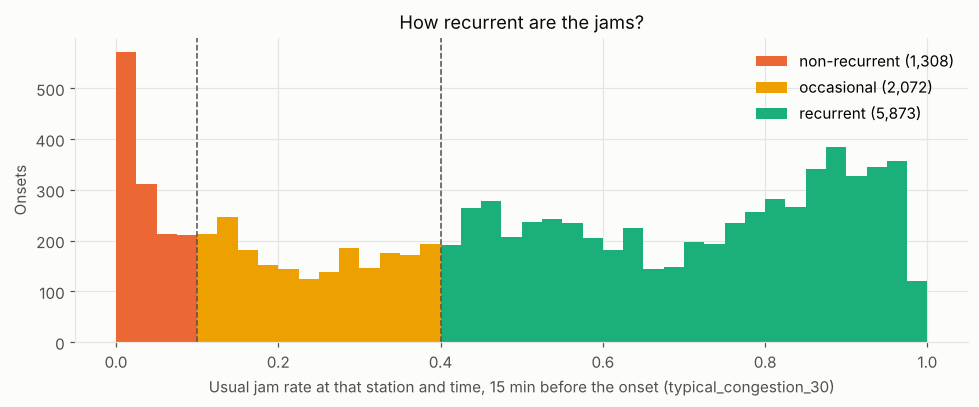

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 41)
for group in GROUPS:
    part = onsets.loc[onsets["group"] == group, "recurrence"]
    ax.hist(part, bins=bins, color=GROUP_COLORS[group], label=f"{group} ({len(part):,})")
for cut in RECURRENCE_CUTS:
    ax.axvline(cut, color=INK2, linewidth=1, linestyle="--")
ax.set_xlabel("Usual jam rate at that station and time, 15 min before the onset (typical_congestion_30)")
ax.set_ylabel("Onsets")
ax.set_title("How recurrent are the jams?")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Models vs. timetable, at the same false-alarm budget
Each one's alert threshold is set so that it raises **`FALSE_ALARM_BUDGET` false-alarm episodes per day** (first view) or **`WRONG_HOURS_BUDGET`
wrong-alert hours per day** (second view). The timetable's wrong alerts come in a few long blocks (it switches on at the same hours every day), so
the two views can disagree. Then: what share of each group's jams does each one catch at least 15 minutes ahead?

False alarms are counted as in `sf.alert_metrics` (an episode = an unbroken stretch of wrong alerts at one station).

In [7]:
DAYS = all_val["date"].nunique()
same_station_before = ((all_val["station"].to_numpy()[1:] == all_val["station"].to_numpy()[:-1])
                       & (np.diff(all_val["timestamp"].to_numpy()) == np.timedelta64(5, "m")))
known_not_y = (all_val["y_known"] & ~all_val["y"]).to_numpy()


def false_alarms(probability, threshold):
    # False-alarm episodes per day and wrong-alert hours per day, as in sf.alert_metrics (fast version for searching).
    false_alarm = (probability >= threshold) & known_not_y
    continues = np.concatenate([[False], false_alarm[1:] & false_alarm[:-1] & same_station_before])
    return {"false alarms / day": (false_alarm & ~continues).sum() / DAYS, "wrong-alert hours / day": false_alarm.sum() * 5 / 60 / DAYS}


def threshold_for(column, measure, budget):
    # The lowest threshold whose false alarms stay within the budget (false alarms fall as the threshold rises).
    probability = all_val[column].to_numpy()
    low, high = 0.0, 1.0
    for _ in range(16):
        middle = (low + high) / 2
        if false_alarms(probability, middle)[measure] > budget:
            low = middle
        else:
            high = middle
    return high


def lead_minutes(column, threshold, rows):
    # For each onset in rows: how early the earliest alert came (0 = no alert in the 30 minutes before), as in sf.alert_metrics.
    alert = pd.Series(all_val[column].to_numpy() >= threshold, index=pd.MultiIndex.from_frame(all_val[sf.KEY]))
    lead = np.zeros(len(rows))
    for step in range(1, sf.STEPS_AHEAD + 1):
        found = alert.reindex(pd.MultiIndex.from_arrays([rows["station"], rows["timestamp"] - pd.Timedelta(minutes=5 * step)]))
        lead = np.where(found.fillna(False).astype(bool).to_numpy(), 5 * step, lead)
    return lead


views = {"same false-alarm episodes": ("false alarms / day", FALSE_ALARM_BUDGET),
         "same wrong-alert hours": ("wrong-alert hours / day", WRONG_HOURS_BUDGET)}
thresholds, budget_rows = {}, []
for view, (measure, budget) in views.items():
    for column in WHO:
        threshold = threshold_for(column, measure, budget)
        thresholds[(view, column)] = threshold
        onsets[f"lead, {column}, {view}"] = lead_minutes(column, threshold, onsets)
        check = sf.alert_metrics(all_val, all_val[column].to_numpy(), threshold)
        budget_rows.append({"view": view, "who": column, "threshold": round(threshold, 3),
                            "false alarms / day": round(check["false alarms / day"], 1),
                            "wrong-alert hours / day": round(check["wrong-alert hours / day"], 2),
                            "caught ≥15 min (all onsets)": round(check["caught ≥15 min"], 3)})
pd.DataFrame(budget_rows).set_index(["view", "who"])

threshold  false alarms / day  wrong-alert hours / day  caught ≥15 min (all onsets)
view                      who                                                                                             
same false-alarm episodes timetable        0.468                20.0                    10.07                        0.576
                          16 features      0.695                20.0                     2.84                        0.436
                          29 features      0.693                20.0                     2.71                        0.462
same wrong-alert hours    timetable        0.733                 9.0                     4.00                        0.336
                          16 features      0.597                25.6                     4.00                        0.544
                          29 features      0.579                26.6                     4.00                        0.572

In [8]:
def caught(view, column, rows=None):
    rows = onsets if rows is None else rows
    return rows[f"lead, {column}, {view}"] >= sf.MIN_LEAD_MIN


catch_rows = []
for view in views:
    for group in GROUPS + ["all"]:
        part = onsets if group == "all" else onsets[onsets["group"] == group]
        row = {"view": view, "group": group, "onsets": len(part)}
        row.update({column: caught(view, column, part).mean() for column in WHO})
        row["29 minus timetable"] = row["29 features"] - row["timetable"]
        row["29 minus 16"] = row["29 features"] - row["16 features"]
        catch_rows.append(row)
catch_table = pd.DataFrame(catch_rows)
catch_table.set_index(["view", "group"]).round(3)

onsets  timetable  16 features  29 features  29 minus timetable  29 minus 16
view                      group                                                                                      
same false-alarm episodes non-recurrent    1308      0.000        0.030        0.016               0.016       -0.014
                          occasional       2072      0.018        0.143        0.146               0.128        0.003
                          recurrent        5873      0.905        0.632        0.676              -0.229        0.044
                          all              9253      0.579        0.438        0.464              -0.115        0.027
same wrong-alert hours    non-recurrent    1308      0.000        0.050        0.039               0.039       -0.011
                          occasional       2072      0.000        0.233        0.262               0.262        0.029
                          recurrent        5873      0.532        0.767        0.804               0.272        0.037
                          all              9253      0.338        0.546        0.574               0.237        0.028

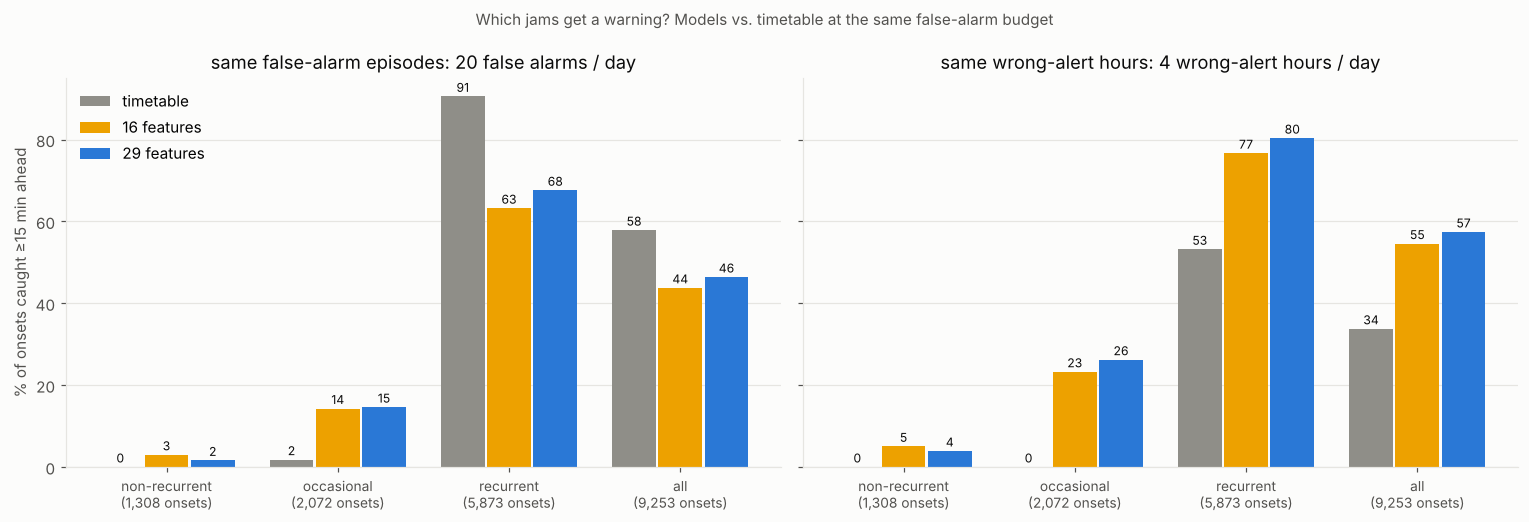

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
x = np.arange(len(GROUPS) + 1)
width = 0.27
for ax, view in zip(axes, views):
    part = catch_table[catch_table["view"] == view].set_index("group").reindex(GROUPS + ["all"])
    for k, column in enumerate(WHO):
        positions = x + (k - 1) * width
        ax.bar(positions, part[column] * 100, width=width * 0.95, color=COLORS[column], label=column)
        for xi, value in zip(positions, part[column] * 100):
            ax.annotate(f"{value:.0f}", (xi, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set_xticks(x, [f"{g}\n({n:,} onsets)" for g, n in zip(part.index, part["onsets"])], fontsize=9)
    measure, budget = views[view]
    ax.set_title(f"{view}: {budget} {measure.split(' / ')[0]} / day")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"% of onsets caught ≥{sf.MIN_LEAD_MIN} min ahead")
axes[0].legend(loc="upper left")
plt.suptitle("Which jams get a warning? Models vs. timetable at the same false-alarm budget", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

**How to read this.** The timetable can only warn about jams that happen at the usual times, so it should catch almost none of the
**non-recurrent** ones. A model's catch rate in that group is what it adds beyond the schedule. In the **recurrent** group, all should do well.
The gap between the **16** and the **29** in each group shows where the 13 extra features help.

**Ranking within each group.** The same question with the main metric: *AP, onsets* on the rows not congested now, split by the row's own
usual jam rate. Each group has its own base rate (the AP of random guessing), so compare each AP with it.

In [10]:
scored = all_val[all_val["y_known"] & ~all_val["congested_now"] & all_val["real"]]
row_group = pd.cut(scored["typical_congestion_30"].fillna(0), [-np.inf, *RECURRENCE_CUTS, np.inf], labels=GROUPS, right=False)
ap_rows = []
for group in GROUPS:
    part = scored[row_group == group]
    row = {"group": group, "rows": len(part), "congested within 30 min (= random AP)": part["y"].mean()}
    row.update({f"AP {column}": average_precision_score(part["y"], part[column]) for column in WHO})
    ap_rows.append(row)
ap_table = pd.DataFrame(ap_rows).set_index("group")
ap_table["AP 29 minus 16"] = ap_table["AP 29 features"] - ap_table["AP 16 features"]
ap_table.round(3)

,rows,congested within 30 min (= random AP),AP timetable,AP 16 features,AP 29 features,AP 29 minus 16
group,,,,,,
non-recurrent,1330797,0.007,0.033,0.221,0.267,0.045
occasional,120964,0.127,0.190,0.502,0.526,0.024
recurrent,106866,0.492,0.659,0.852,0.867,0.015


## 5. Where does the model miss jams?
Catch rate per station along the corridor (direction of travel: postmile increases northbound), at the same false-alarm episodes as above.
Dot size = number of onsets at the station. Stations near the north end (PM ~116.6) can't see jams beyond the data's edge.

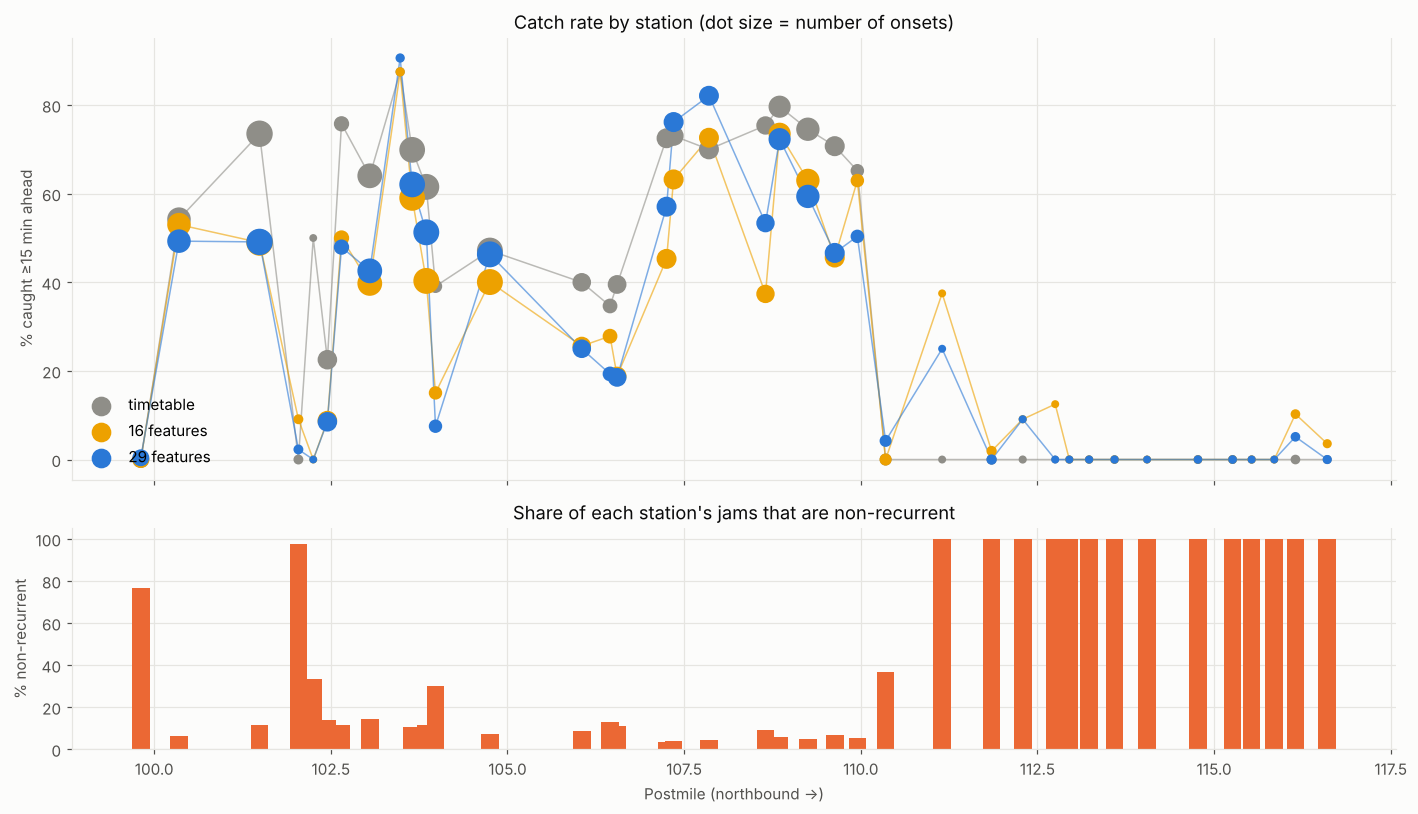

Stations with the lowest catch rate for the 29-feature model (at least 50 onsets):


,name,pm,onsets,non_recurrent,timetable,16 features,29 features
station,,,,,,,
1205517,EUCLID 2,111.850998,52,1.000,0.000,0.019,0.000
1205071,JAMBOREE 2,99.810997,253,0.767,0.000,0.000,0.004
1205473,SOUTH 2,110.350998,95,0.368,0.000,0.000,0.042
1205225,GRAND 2,103.981003,133,0.301,0.391,0.150,0.075
1205165,S OF 55,102.450996,364,0.140,0.225,0.088,0.085
1205330,N OF 57,106.551003,329,0.112,0.395,0.188,0.185
1205320,LA VETA,106.450996,176,0.131,0.347,0.278,0.193
1205303,S OF 22,106.051003,320,0.088,0.400,0.256,0.250


In [11]:
VIEW = "same false-alarm episodes"
for column in WHO:
    onsets[f"caught, {column}"] = caught(VIEW, column)

per_station = onsets.groupby("station").agg(onsets=("onset", "size"), pm=("pm", "first"),
                                            non_recurrent=("group", lambda g: (g == "non-recurrent").mean()),
                                            **{column: (f"caught, {column}", "mean") for column in WHO})
per_station["name"] = per_station.index.map(stations["Name"])
per_station = per_station.sort_values("pm")

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
size = 15 + 250 * per_station["onsets"] / per_station["onsets"].max()
for column in WHO:
    axes[0].plot(per_station["pm"], per_station[column] * 100, color=COLORS[column], linewidth=1, alpha=0.6)
    axes[0].scatter(per_station["pm"], per_station[column] * 100, s=size, color=COLORS[column], label=column, zorder=3)
axes[0].set_ylabel(f"% caught ≥{sf.MIN_LEAD_MIN} min ahead")
axes[0].set_title("Catch rate by station (dot size = number of onsets)")
axes[0].legend(loc="lower left")
axes[1].bar(per_station["pm"], per_station["non_recurrent"] * 100, width=0.25, color=GROUP_COLORS["non-recurrent"])
axes[1].set_ylabel("% non-recurrent")
axes[1].set_xlabel("Postmile (northbound →)")
axes[1].set_title("Share of each station's jams that are non-recurrent")
plt.tight_layout()
plt.show()

print("Stations with the lowest catch rate for the 29-feature model (at least 50 onsets):")
per_station[per_station["onsets"] >= 50].sort_values("29 features").head(8)[["name", "pm", "onsets", "non_recurrent"] + WHO].round(3)

## 6. When does it miss them?
Catch rate by the hour the jam starts, by weekday and by validation quarter (same false-alarm episodes as above). Gray bars = number of onsets.

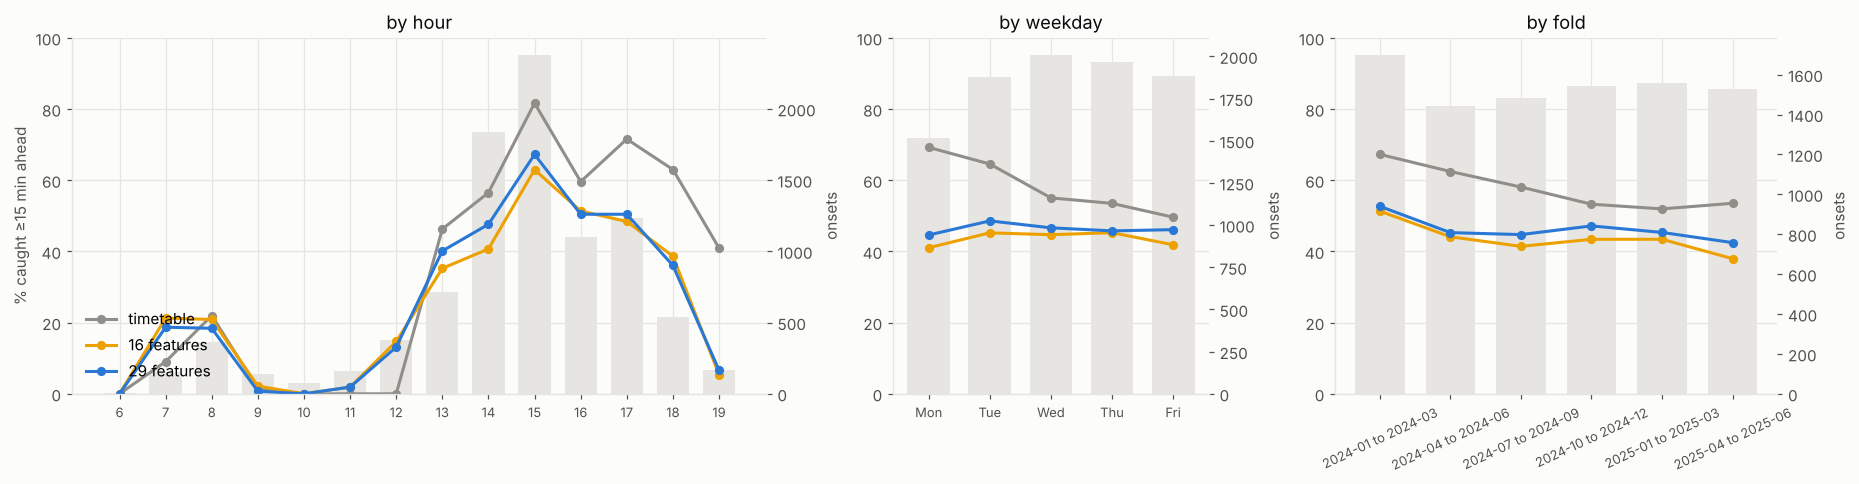

29-feature model: % caught by hour and group


group,non-recurrent,occasional,recurrent
hour,,,
6,0.0,NaN,NaN
7,1.0,30.0,58.0
8,2.0,4.0,51.0
9,0.0,0.0,100.0
10,0.0,0.0,NaN
11,1.0,4.0,NaN
12,0.0,12.0,40.0
13,2.0,10.0,65.0
14,5.0,26.0,63.0


In [12]:
onsets["hour"] = onsets["timestamp"].dt.hour
onsets["weekday"] = onsets["timestamp"].dt.day_name().str[:3]
by = {"hour": list(range(6, 20)), "weekday": ["Mon", "Tue", "Wed", "Thu", "Fri"], "fold": sorted(onsets["fold"].unique())}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [2.2, 1, 1.4]})
for ax, (column, order) in zip(axes, by.items()):
    table = onsets.groupby(column).agg(onsets=("onset", "size"),
                                       **{name: (f"caught, {name}", "mean") for name in WHO}).reindex(order)
    x = np.arange(len(order))
    counts = ax.twinx()
    counts.bar(x, table["onsets"], color=GRID, width=0.7, zorder=0)
    counts.set_ylabel("onsets", color=INK2)
    counts.grid(False)
    ax.set_zorder(counts.get_zorder() + 1)
    ax.patch.set_visible(False)
    for name in WHO:
        ax.plot(x, table[name] * 100, color=COLORS[name], marker="o", markersize=5, label=name)
    ax.set_xticks(x, [str(v) for v in order], rotation=0 if column != "fold" else 25, fontsize=8.5)
    ax.set_ylim(0, 100)
    ax.set_title(f"by {column}")
axes[0].set_ylabel(f"% caught ≥{sf.MIN_LEAD_MIN} min ahead")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

print("29-feature model: % caught by hour and group")
onsets.groupby(["hour", "group"], observed=True)["caught, 29 features"].mean().unstack().reindex(columns=GROUPS).mul(100).round(0)

## 7. What do missed jams look like at warning time?
Conditions 15 minutes before each onset, for the jams the 29-feature model caught and the ones it missed (the table at the end also compares the
16 and the 29 under each condition):
- **speed here:** a station still at 65 mph 15 minutes before a jam gives little warning (a sudden jam);
- **a jam downstream:** a congested station within `sf.DOWNSTREAM_MILES` miles ahead (`jam_distance_down` below that distance).

(Whether the reading at warning time was measured isn't a factor here: an onset needs 30 measured minutes before it, so it always was.)

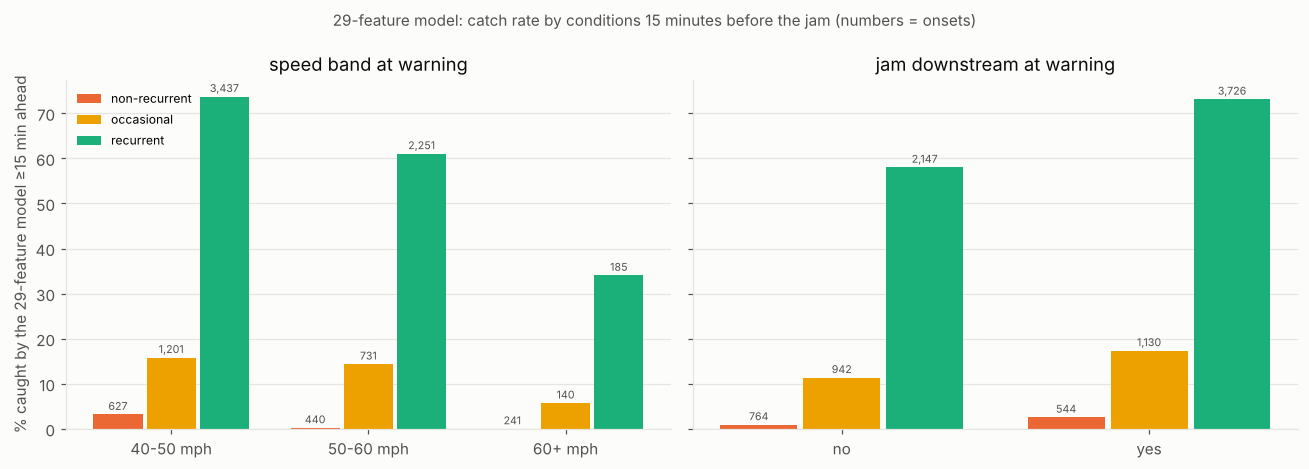

% caught under each condition: 16 vs. 29 features


timetable  16 features  29 features
speed band at warning     40-50 mph       58.8         53.5         52.1
                          50-60 mph       60.9         35.0         43.2
                          60+ mph         31.3          6.4         12.5
jam downstream at warning no              48.6         32.1         35.3
                          yes             64.5         52.1         54.4

Median conditions at warning time, jams the 29-feature model caught vs. missed


speed at warning  downstream_speed at warning  min_speed_down at warning  jam_distance_down at warning  minutes_since_slow at warning  \
group         outcome                                                                                                                                          
non-recurrent caught          45.700001                    40.799999                  35.500000                          1.20                          120.0   
              missed          50.599998                    52.000000                  42.799999                          5.00                          120.0   
occasional    caught          47.099998                    45.700001                  36.599998                          1.40                          120.0   
              missed          48.400002                    49.099998                  39.000000                          2.70                          120.0   
recurrent     caught          46.500000                    46.700001                  36.200001                          1.20                          120.0   
              missed          50.599998                    51.099998                  39.000000                          2.44                          120.0   

                       recurrence  
group         outcome              
non-recurrent caught         0.03  
              missed         0.03  
occasional    caught         0.33  
              missed         0.22  
recurrent     caught         0.82  
              missed         0.57

In [13]:
onsets["speed band at warning"] = pd.cut(onsets["speed at warning"], [0, 50, 60, np.inf], labels=["40-50 mph", "50-60 mph", "60+ mph"],
                                         right=False)
onsets["jam downstream at warning"] = np.where(onsets["jam_distance_down at warning"] < sf.DOWNSTREAM_MILES, "yes", "no")
factors = ["speed band at warning", "jam downstream at warning"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, factor in zip(axes, factors):
    table = onsets.groupby([factor, "group"], observed=True)["caught, 29 features"].agg(["mean", "size"]).reset_index()
    levels = list(onsets[factor].dropna().unique()) if factor != "speed band at warning" else ["40-50 mph", "50-60 mph", "60+ mph"]
    levels = sorted(levels) if factor != "speed band at warning" else levels
    x = np.arange(len(levels))
    for k, group in enumerate(GROUPS):
        part = table[table["group"] == group].set_index(factor).reindex(levels)
        ax.bar(x + (k - 1) * 0.27, part["mean"] * 100, width=0.25, color=GROUP_COLORS[group], label=group)
        for xi, (value, n) in zip(x + (k - 1) * 0.27, zip(part["mean"] * 100, part["size"])):
            if not np.isnan(value):
                ax.annotate(f"{int(n):,}", (xi, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color=INK2)
    ax.set_xticks(x, levels)
    ax.set_title(factor)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"% caught by the 29-feature model ≥{sf.MIN_LEAD_MIN} min ahead")
axes[0].legend(loc="upper left", fontsize=8)
plt.suptitle("29-feature model: catch rate by conditions 15 minutes before the jam (numbers = onsets)", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

print("% caught under each condition: 16 vs. 29 features")
display(pd.concat({factor: onsets.groupby(factor, observed=True)[[f"caught, {c}" for c in WHO]].mean().mul(100).round(1)
                   for factor in factors}).rename(columns=lambda c: c.replace("caught, ", "")))

print("Median conditions at warning time, jams the 29-feature model caught vs. missed")
summary_columns = ["speed at warning", "downstream_speed at warning", "min_speed_down at warning", "jam_distance_down at warning",
                   "minutes_since_slow at warning", "recurrence"]
(onsets.assign(outcome=np.where(onsets["caught, 29 features"], "caught", "missed"))
 .groupby(["group", "outcome"], observed=True)[summary_columns].median().round(2))

## 8. Close-ups: missed and caught unusual jams
The corridor's speeds from 60 minutes before to 30 minutes after a non-recurrent onset: time runs left to right, postmile bottom to top (traffic
moves up). Red = slow. The dashed line marks the station, the vertical line the onset. A jam whose slow area **reaches the station from above**
came from downstream and could be seen coming; one that **appears at the station** gave no warning. Below each: both models' probabilities at the
station, with their alert thresholds (dashed).

`N_EXAMPLES` non-recurrent onsets the 29-feature model missed (chosen at random) and 2 it caught, for contrast.

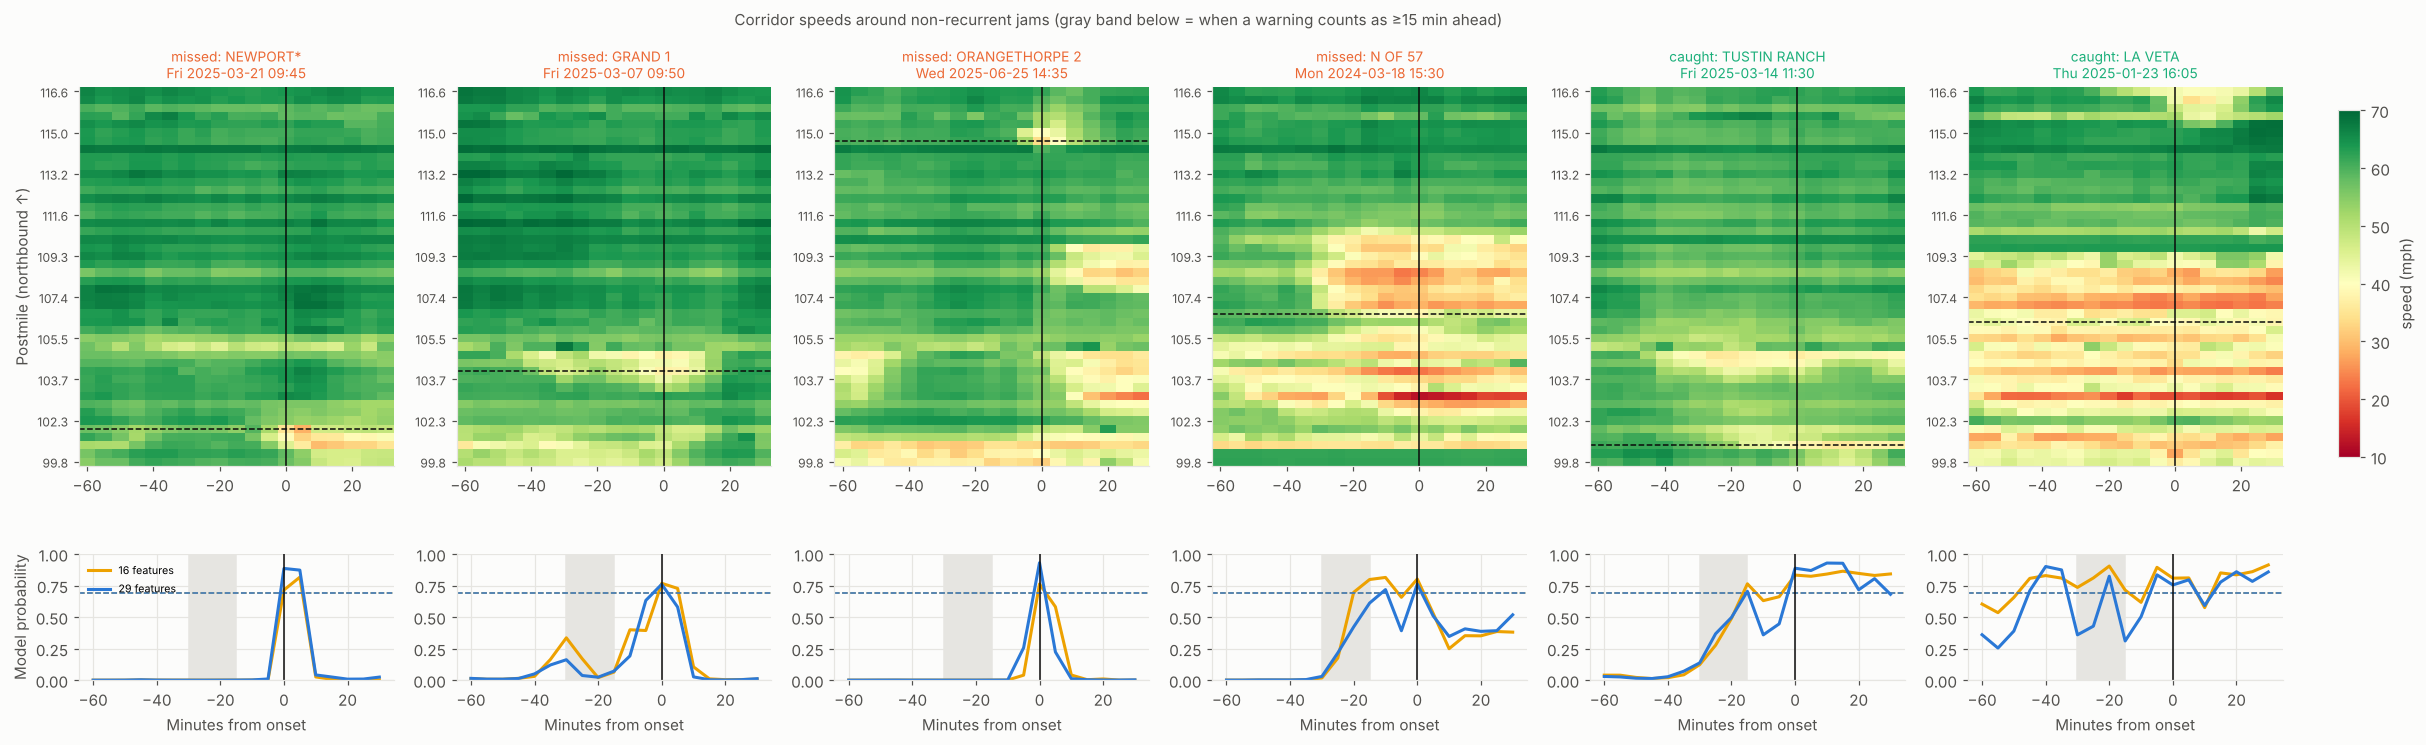

In [14]:
order = stations.sort_values("travel_pm")
speed_by_key = df.set_index(sf.KEY)["speed"]
rng = np.random.default_rng(0)
unusual = onsets[onsets["group"] == "non-recurrent"]
missed = unusual[~unusual["caught, 29 features"]]
hit = unusual[unusual["caught, 29 features"]]
examples = [("missed", row) for _, row in missed.iloc[rng.choice(len(missed), min(N_EXAMPLES, len(missed)), replace=False)].iterrows()]
examples += [("caught", row) for _, row in hit.iloc[rng.choice(len(hit), min(2, len(hit)), replace=False)].iterrows()]

fig, axes = plt.subplots(2, len(examples), figsize=(4.2 * len(examples), 7), gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
for k, (outcome, onset) in enumerate(examples):
    times = pd.date_range(onset["timestamp"] - pd.Timedelta(minutes=60), onset["timestamp"] + pd.Timedelta(minutes=30), freq="5min")
    grid = speed_by_key.reindex(pd.MultiIndex.from_product([order.index, times])).to_numpy().reshape(len(order), len(times))
    ax = axes[0, k]
    ax.imshow(grid, aspect="auto", origin="lower", cmap="RdYlGn", vmin=10, vmax=70, extent=[-62.5, 32.5, -0.5, len(order) - 0.5])
    ax.axhline(order.index.get_loc(onset["station"]), color=INK, linestyle="--", linewidth=1)
    ax.axvline(0, color=INK, linewidth=1)
    ticks = np.arange(0, len(order), 5)
    ax.set_yticks(ticks, [f"{pm:.1f}" for pm in order["Abs_PM"].to_numpy()[ticks]], fontsize=8)
    ax.grid(False)
    ax.set_title(f"{outcome}: {stations.loc[onset['station'], 'Name']}\n{onset['timestamp']:%a %Y-%m-%d %H:%M}", fontsize=9,
                 color=ORANGE if outcome == "missed" else AQUA)
    if k == 0:
        ax.set_ylabel("Postmile (northbound ↑)")

    ax = axes[1, k]
    for name in ["16 features", "29 features"]:
        probability = by_key[name].reindex(pd.MultiIndex.from_product([[onset["station"]], times])).to_numpy()
        ax.plot(np.arange(-60, 31, 5), probability, color=COLORS[name], label=name)
        ax.axhline(thresholds[(VIEW, name)], color=COLORS[name], linestyle="--", linewidth=1)
    ax.axvline(0, color=INK, linewidth=1)
    if k == 0:
        ax.legend(fontsize=7, loc="upper left")
    ax.axvspan(-30, -sf.MIN_LEAD_MIN, color=GRID, zorder=0)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Minutes from onset")
    if k == 0:
        ax.set_ylabel("Model probability")
fig.subplots_adjust(right=0.92, hspace=0.35)
fig.colorbar(axes[0, -1].images[0], cax=fig.add_axes([0.94, 0.4, 0.008, 0.45]), label="speed (mph)")
plt.suptitle("Corridor speeds around non-recurrent jams (gray band below = when a warning counts as ≥15 min ahead)", color=INK2, fontsize=10)
plt.show()

## 9. Notes

- **Most jams follow the daily schedule.** 64% of the 9,253 validation onsets are recurrent (the station jams at that time on more than 40% of
  days), 22% occasional and 14% non-recurrent.
- **Neither model warns about unusual jams in time.** At the same false-alarm budget, the 29-feature model catches 2–4% of non-recurrent onsets at
  least 15 minutes ahead, and the 16-feature model 3–5%; the timetable catches none. So the model's warnings are, in practice, warnings about the
  usual jams.
- **It does sense unusual jams, just not early or strongly enough to alert.** Among rows with a usual jam rate below 10%, the 29-feature model's
  AP is 0.27 against 0.007 for random guessing (about 38 times better) and 0.03 for the timetable. The close-ups show why: its probability rises
  only in the last 5–10 minutes, often after a slowdown is already visible at the station or just downstream.
- **What decides whether a jam is caught is whether it is already visible.** 15 minutes before a jam, if the station is still at 60+ mph the
  29-feature model catches 13%; at 40–50 mph, 52%. With a congested station within 5 miles downstream it catches 54%, without one 35%. Missed
  unusual jams had a median downstream speed of 52 mph at warning time, against 41 mph for caught ones: they appear without a visible queue
  ahead (incidents, or slowdowns starting at the station itself).
- **Which false alarms count changes the verdict against the timetable.** With the same number of false-alarm *episodes* (20 per day), the
  timetable catches more jams overall (58% vs. 46%), because its wrong alerts come in a few long blocks: it pays for that with 10 wrong-alert
  hours per day against 2.7 for the model. With the same wrong-alert *time* (4 hours per day), the model catches far more (57% vs. 34%), and
  even beats the timetable on recurrent jams (80% vs. 53%). For a map, wrong-alert time is arguably the fairer budget.
- **The 13 extra features help mostly with the usual jams.** The 29 catch 3–4 points more recurrent onsets than the 16 and about the
  same share of unusual ones. In ranking, though, their largest gain is on the unusual rows (AP +0.045, against +0.015 on recurrent ones): the
  recent-history features do pick up today's conditions, but not early enough to turn into alerts.
- **Where it fails:** stations north of about PM 111 have few jams and nearly all are non-recurrent, so almost none are caught. Among busy
  stations, the worst are near the south end (Jamboree 2, PM 99.8: 253 onsets, 77% non-recurrent, almost none caught) and a few interchange
  stations (Grand 2, S of 55, N of 57, La Veta, S of 22), where even the timetable does better than the model at the same number of episodes.
- **When it fails:** mid-morning (9:00–12:00) jams are almost never caught: few happen and they are rarely part of the pattern. The morning
  peak (7:00–8:00) is caught only about 20% of the time; the afternoon peak (14:00–17:00) is where most warnings work (up to 67% at 15:00).
  The models catch about the same share every weekday, while the timetable does best on Mondays. Catch rates fall from early 2024 to 2025 for every
  method, the timetable included, so this is more likely a change in traffic than a weakness of the models.
- **No incident or weather data is used.** "Non-recurrent" means rare at that station and time, not caused by an incident.